### *Mauricio Rios Cantillo - Jose Bonett Pertuz - Jorge Jaraba Potes - Jordan Caro Batista*

##### **CLASIFICACION DE VOCALES QUE ESTAN EN IMAGENES POR MEDIO DE MACHINE LEARNING**
---

# Descripción del problema

En el presente trabajo se busca construir un modelo de aprendizaje automático capaz de identificar qué vocal (A, E, I, O o U) aparece en una imagen. Se trata de un problema de **clasificación supervisada multiclase**: cada imagen pertenece a una sola de las cinco clases.

El conjunto de datos original de Kaggle(https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset) contiene 35 carpetas con imágenes de letras y números. Para este trabajo se extrajeron manualmente únicamente las carpetas de las vocales, que son las clases que se requiere identificar. La vocal **O** corresponde a la carpeta `0`.

Objetivos específicos:

*   Explorar y describir el conjunto de imágenes de vocales.
*   Aplicar técnicas de procesamiento a las imágenes (conversión a escala de grises, entre otras).
*   Implementar y evaluar modelos de aprendizaje de máquina para clasificar las vocales.

#### Objetivo de esta etapa

Antes de entrenar cualquier modelo, en esta etapa se busca comprender cómo está organizado el conjunto de datos y verificar su calidad: la cantidad de imágenes por vocal, sus dimensiones, número de canales y formato, la distribución de ejemplos entre clases y las variaciones visuales entre imágenes. Como parte del preprocesamiento, las imágenes se convertirán a escala de grises para garantizar que todas tengan un único canal.

### Descripción de variables

El conjunto de datos está formado por imágenes organizadas en carpetas, una por cada vocal:

*   La variable predictora **X** corresponde a la imagen de la vocal. Cada imagen se representa como una matriz de píxeles con valores de intensidad entre 0 (negro) y 255 (blanco).
*   La variable objetivo **Y** corresponde a la vocal que aparece en la imagen (A, E, I, O, U). Se obtiene del nombre de la carpeta que contiene cada imagen.

#### Importación de librerías

Se importan las librerías necesarias para recorrer las carpetas del dataset, leer y procesar las imágenes, organizar los datos en tablas y construir las visualizaciones.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import skimage as ski
import os
import pandas as pd
import numpy as np
import statistics
import skimage.io as io
import skimage.exposure as ske
import warnings


from pathlib import Path
from skimage.color import rgb2gray
from skimage.transform import resize



from sklearn.preprocessing import MinMaxScaler


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score
from sklearn import metrics


from sklearn.metrics import classification_report
from sklearn import tree


from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning


### Cargando el conjunto de datos

El conjunto de datos está organizado en carpetas, una por cada vocal. A continuación se listan las carpetas que contiene.

In [5]:
RUTA = "Only Vowels"
carpetas = sorted(os.listdir(RUTA))
print("Carpetas encontradas:", carpetas)
print("Número de carpetas:", len(carpetas))

Carpetas encontradas: ['0', 'A', 'E', 'I', 'U']
Número de carpetas: 5


El conjunto de datos contiene 5 carpetas: `0`, `A`, `E`, `I` y `U`. Cada carpeta corresponde a una clase (vocal), y el nombre de la carpeta es la etiqueta de las imágenes que contiene. La carpeta `0` contiene las imágenes de la vocal **O**.

### Archivos del conjunto de datos

Se revisan los nombres de los archivos de una carpeta y las extensiones presentes en todo el conjunto de datos.

In [27]:
archivos_A = sorted(os.listdir(os.path.join(RUTA, "A")))
print("Primeros 5 archivos de la carpeta A  :")
for archivo in archivos_A[:5]:
    print("  ", archivo)

extensiones = {os.path.splitext(f)[1].lower()
               for c in carpetas
               for f in os.listdir(os.path.join(RUTA, c))}
print("Extensiones encontradas en todo el dataset:", extensiones)

Primeros 5 archivos de la carpeta A  :
   aug100_19.jpg
   aug100_9.jpg
   aug101_0.jpg
   aug102_1.jpg
   aug103_2.jpg
Extensiones encontradas en todo el dataset: {'.jpg'}


Todas las imágenes están en formato **JPEG** (`.jpg`). Los archivos siguen el patrón `augNNNN_N.jpg`

### Número de casos

Se cuenta la cantidad de imágenes de cada vocal y el total del conjunto de datos.

In [28]:
nombre_vocal = {"0": "O", "A": "A", "E": "E", "I": "I", "U": "U"}

conteos = []
for carpeta in carpetas:
    cantidad = len(os.listdir(os.path.join(RUTA, carpeta)))
    conteos.append({"Vocal": nombre_vocal[carpeta], "Carpeta": carpeta, "Cantidad": cantidad})

df_conteos = pd.DataFrame(conteos).sort_values("Vocal").reset_index(drop=True)
df_conteos["Porcentaje (%)"] = (df_conteos["Cantidad"] / df_conteos["Cantidad"].sum() * 100).round(2)

print(df_conteos.to_string(index=False))
print("\nTotal de imágenes (casos):", df_conteos["Cantidad"].sum())

Vocal Carpeta  Cantidad  Porcentaje (%)
    A       A      1010           19.92
    E       E      1010           19.92
    I       I      1010           19.92
    O       0      1030           20.32
    U       U      1010           19.92

Total de imágenes (casos): 5070


El conjunto de datos tiene **5070 casos** (imágenes). Las vocales A, E, I y U tienen 1010 imágenes cada una (19,92 %), y la vocal O tiene 1030 (20,32 %).

### Distribución de las clases

En la siguiente gráfica de barras se observa la cantidad de imágenes por vocal.

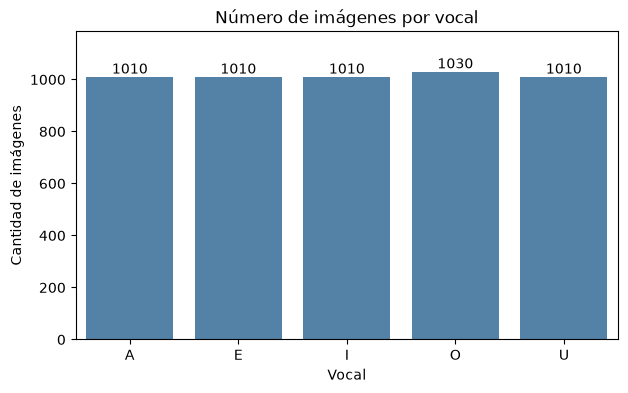

In [29]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_conteos, x="Vocal", y="Cantidad", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Número de imágenes por vocal")
plt.xlabel("Vocal")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, df_conteos["Cantidad"].max() * 1.15)
plt.show()

Las clases están **balanceadas**: la diferencia entre la clase más grande (O, 1030) y las demás (1010) es de solo 20 imágenes, menos del 2 %. Esto evita que un modelo se incline hacia una clase en particular.

### Representación de las imágenes

Se muestra un ejemplo de cada vocal y se revisa cómo se representa una imagen internamente, es decir, la variable predictora X.

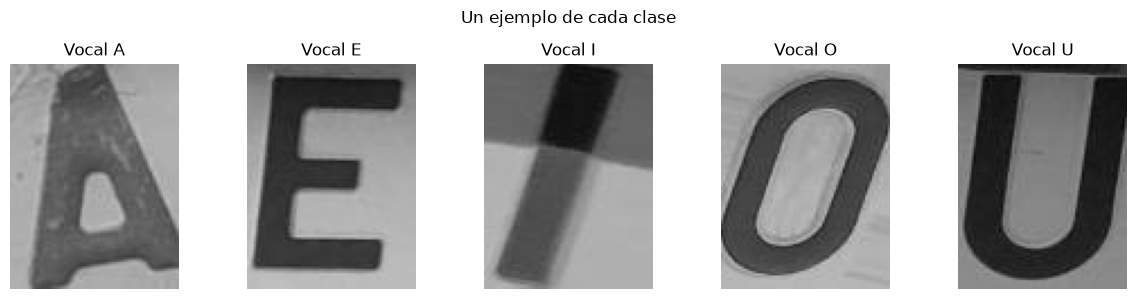

In [30]:
fig, axes = plt.subplots(1, len(carpetas), figsize=(12, 3))
for ax, carpeta in zip(axes, sorted(carpetas, key=lambda c: nombre_vocal[c])):
    primer_archivo = sorted(os.listdir(os.path.join(RUTA, carpeta)))[0]
    img = ski.io.imread(os.path.join(RUTA, carpeta, primer_archivo))
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Vocal {nombre_vocal[carpeta]}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada clase")
plt.tight_layout()
plt.show()

In [31]:
ruta_ejemplo = os.path.join(RUTA, "A", archivos_A[0])
img = ski.io.imread(ruta_ejemplo)

print("Archivo:", ruta_ejemplo)
print("Tipo de objeto:", type(img))
print("Forma (alto, ancho):", img.shape)
print("Número de dimensiones:", img.ndim)
print("Tipo de dato:", img.dtype)
print("Valor mínimo:", img.min(), "| Valor máximo:", img.max())
print("Número total de píxeles (variables de entrada):", img.size)
print("\nFragmento de la matriz (filas 45 a 49, columnas 30 a 37):")
print(img[45:50, 30:38])

Archivo: Only Vowels\A\aug100_19.jpg
Tipo de objeto: <class 'numpy.ndarray'>
Forma (alto, ancho): (100, 75)
Número de dimensiones: 2
Tipo de dato: uint8
Valor mínimo: 59 | Valor máximo: 194
Número total de píxeles (variables de entrada): 7500

Fragmento de la matriz (filas 45 a 49, columnas 30 a 37):
[[ 83  83  82  81  79  77  76  77]
 [ 82  80  79  77  74  72  71  73]
 [ 82  79  77  75  71  68  68  71]
 [ 79  80  74  70  69  87 114 122]
 [ 81  79  65  76  91 119 149 158]]


Cada imagen se carga como un arreglo de NumPy de forma **(100, 75)**: 100 píxeles de alto por 75 de ancho. Tiene **2 dimensiones**, lo que indica que está en escala de grises (un solo canal). Los valores son enteros de 8 bits (`uint8`) en el rango 0–255, donde 0 es negro y 255 blanco. En total, cada imagen aporta **7500 píxeles**, que son los valores numéricos con los que el modelo trabajará como variable predictora X.